> **仓库整理提示｜2026-11-23**：本篇来自已保存的中文学习版，不保证包含个人电脑上的后续修改。本次未重新执行真实数据；保留输出仅作示例，不是本次复现记录。
>
> 先阅读 [运行指南](../../guides/setup.md) 和 [版本来源](SOURCES.md)。从前往后执行，辅助函数必须先定义再调用。下面开始原中文学习版正文。


# **教程 4：坐标检查、时间轴修正与光纤地理位置**

> **中文版 v2｜2026-10-05**。基于 [xdas-dev/tutorials：04_playing_with_coordinates.ipynb](https://github.com/xdas-dev/tutorials/blob/main/04_playing_with_coordinates.ipynb) 汉化，保留原教程代码顺序与示例输出；补充说明不代表原作者观点。原项目采用 GPL-3.0 许可证。
>
> **稚方Xttus × ChatGPT（Codex）｜共同整理，边学边完善**。

## **学习目的与数据背景**

DAS 波形的每个数值都需要对应“什么时候、光纤哪里”。若时间戳局部回退、距离单位弄错或几何信息缺失，即使波形能画出来，选择与分析也可能出错。本教程学习如何检查和使用这些坐标。

| 部分 | 学习问题 | 得到什么 |
| --- | --- | --- |
| 1. 坐标类型与规则性 | 轴怎样存储，采样间隔为何要声明？ | 理解坐标对象与采样声明 |
| 2. NTP 时间轴 | 小计时偏差和真实缺口怎样区分？ | 修正小偏差，保留真实缺口 |
| 3. 距离单位 | 米改为千米会改变什么？ | 更新距离坐标及其采样声明 |
| 4. 辅助坐标 | 经纬度、名称如何对应通道？ | 理解几何缺失、盘纤与标签跟随 |
| 5. 维度替换与绘图 | 怎样按纬度选择光纤数据？ | 纬度—时间波形图 |

主光纤数据沿用教程一的 `outputs/singlecable.nc`。NTP 示例来自另一批 `data/ntp_sync/*.hdf5`，其采样率与主光纤不同。本教程不以教程三的 `picks.csv` 为输入，也不要求重跑 PhaseNet。

## **先分清：索引、维度、坐标、波形**

| 概念 | 例子 | 含义 |
| --- | --- | --- |
| 索引 index | 第 0、1、2 个通道 | 数组中的位置编号 |
| 维度 dimension | `time`、`distance` | 数组沿哪个方向展开 |
| 维度坐标 | 时间戳、沿纤距离 | 给该维度上的样本提供选择标签 |
| 辅助坐标 | `latitude`、`longitude`、`station` | 与样本对应的附加位置或名称 |
| 波形测量值 | `da` 的数据部分 | DAS 测量，不等于坐标值 |

**规则采样、严格单调、没有缺口是不同条件。**等间隔连续段之间可能有缺口；严格单调坐标也可能非等间隔。后文分别检查，避免用一个概念代替另一个。

## **常用操作的效果对比**

| 操作 | 主要改变什么 | 不会自动完成什么 |
| --- | --- | --- |
| `simplify(tolerance)` | 坐标控制点与容差内的标签偏差 | 恢复丢失的波形或验证绝对时钟精度 |
| `to_regular()` | 转换、声明可表示的规则采样坐标 | 任意波形重采样 |
| `assign_coords(...)` | 替换或添加坐标 | 自动改变测量值的物理单位 |
| `sel(...)` | 按坐标范围选取样本 | 调整采样率 |
| `resample(...)` | 波形采样及对应坐标 | 保留所有细尺度信息 |
| `swap_dims(...)` | 使用哪个坐标作为维度 | 地理投影或等纬度插值 |

## **运行前准备**

将 Notebook 放在教程项目根目录，使用项目 `.venv` 内核，按顺序运行。路径均相对于项目根目录，项目可放在任意磁盘。

需要 `outputs/singlecable.nc` 与 `data/ntp_sync` 下的 HDF5 文件。经纬度应已由教程一写入 `singlecable.nc`；若你生成的是缺少几何坐标的旧版本，需要准备路径信息并重做教程一相关步骤，不能用虚构经纬度替代。

保留的输出是**原作者示例**，不表示你已运行；运行后会被本机结果替换。某些警告是教程刻意演示的问题，后文说明处理方法。坐标 API 与依赖项目版本有关，优先使用与本机原教程配套的环境。

本教程不写入新的输出文件；对 `da` 和 `ntp` 的重新赋值只更新当前会话的对象，不会直接覆盖输入 NetCDF/HDF5 文件。空间重采样会真正计算较大的波形，建议按章节逐格运行，避免无必要地载入所有数据。

下方是明确的正文起点；上方导读不需要单独执行。

---
# **原教程正文开始**

英文原标题为 *Playing with coordinates*。以下保留原教程步骤顺序，穿插中文解释。新增的运行前检查会先确认输入文件。
---

# **坐标操作：检查时间轴与描述光纤位置**

坐标不仅是轴上的刻度，还告诉 XDAS 这套刻度是否满足处理要求，并保存通道编号没有表达的信息：轴如何存储、轴不递增时怎样选择数据、光纤实际位于哪里、通道叫什么，以及哪个附加坐标可以成为选择轴。

In [1]:
import numpy as np
import pandas as pd

import xdas as xd

In [ ]:
from pathlib import Path

print("当前工作目录：", Path.cwd())
if not Path("outputs/singlecable.nc").is_file():
    raise FileNotFoundError("请先运行教程一生成 outputs/singlecable.nc，并确认当前工作目录为项目根目录。")
ntp_files = list(Path("data/ntp_sync").glob("*.hdf5"))
print("NTP 示例文件数：", len(ntp_files))
if not ntp_files:
    raise FileNotFoundError("未找到 data/ntp_sync/*.hdf5，请确认教程数据已完整解压；仅有 singlecable.nc 还不能运行时间轴示例。")


In [2]:
da = xd.open("outputs/singlecable.nc")
da

<xdas.DataArray (time: 37500, distance: 10000)>
VirtualSource: 715.3MB (int16)
Coordinates:
  * distance (distance): 0.000 to 153179.709
  * time (time): 2023-11-03T12:20:01.000 to 2023-11-03T12:30:00.984
    latitude (distance): [nan ... nan]
    longitude (distance): [nan ... nan]

### **打开结果怎样读？**

原示例形状为 `time: 37500, distance: 10000`，时间间隔约 0.016 秒（62.5 Hz）。`VirtualSource` 表示通过虚拟来源引用数据，显示的大小不等于当前内存占用。

坐标列表中 `*` 标记维度坐标，未带 `*` 的经纬度是辅助坐标。`[nan ... nan]` 是省略显示，不能仅凭开头和结尾就认定整个坐标全是缺失值。

这是教程一的数据，再次打开不包含教程二、三内存中的滤波结果。

## **1. 轴坐标的三种存储方式**

轴坐标可以用三种方式表示，以减少不必要的存储：

| 类型 | 中文表述 | 保存什么 |
| --- | --- | --- |
| `DenseCoordinate` | 稠密坐标 | 每一个坐标值，类似 NumPy 数组 |
| `InterpCoordinate` | 插值坐标 | 索引—坐标值控制点（tie points），其间通过插值恢复坐标 |
| `SampledCoordinate` | 分段采样坐标 | 每段的起点、样本数和采样间隔，类似 SEED 对波形段的描述 |

**这里的插值恢复的是坐标，不是填补缺失的波形。**长轴近乎等间隔时，保存少量控制点通常比保存全部标签节省空间。这个示例的两个轴使用插值坐标，下一格查看它们的类型。

In [3]:
type(da["time"]).__name__, type(da["distance"]).__name__

('InterpCoordinate', 'InterpCoordinate')

### **1.1 规则性：为什么要声明采样间隔？**

坐标可以声明一个**标称采样间隔**，并给出允许的抖动容差。信号处理需要这个间隔，才能把秒数、频率或距离与采样点对应起来。

若记录中有缺口，只用“首尾时间差 ÷ 样本间隔数”估计采样间隔，会把停录时间也算进去。下一格检查时间坐标是否声明了规则采样，并读取采样间隔。规则采样的连续段仍可能被真实缺口隔开，`isregular()` 不等于“整段记录无缺口”。

In [4]:
print(da["time"].isregular(), da["time"].get_sampling_interval())

True 0.016


原示例输出 `True 0.016`：时间坐标声明了规则采样，间隔约 0.016 秒。这个值属于主光纤 `da`；后面的 NTP 数据 `ntp` 是 125 Hz，不应混用。

不规则坐标可以尝试用 `to_regular()` 转成规则坐标；`tolerance` 指定允许吸收的坐标抖动。但能否转换取决于底层坐标值，并不是加上这行就一定成功。下一节先检查时间戳，再讨论修正。

## **2. 检查与修正不可靠的时间轴**

这里使用的 `ntp` 是另一批采集数据，不是刚才的 `da`。原教程说明它采用 **NTP（网络时间协议）同步**，文件之间的时间接缝存在小偏差。

`tolerance` 控制连接文件时允许吸收多大的坐标偏差。作者先设置 `tolerance=None`，按原时间戳连接，不提前抹平偏差，目的是**先看见问题，再修正**。这与日常直接使用适当容差打开数据的目标不同。

下一格打开 `data/ntp_sync` 下的 HDF5 文件。`ntp` 与 `da` 是独立变量，本节对 `ntp` 的修改不会自动修改 `da`。

In [5]:
ntp = xd.open("data/ntp_sync/*.hdf5", tolerance=None)
ntp

<xdas.DataArray (time: 8750, distance: 50000)>
VirtualStack: 1.6GB (float32)
Coordinates:
  * distance (distance): 0.000 to 204255.953
  * time (time): 2021-11-11T02:10:40.693 to 2021-11-11T02:20:20.680

### **2.1 为什么打开时没提示，选择时才提示？**

部分坐标检查在真正使用轴时才发生。下一格选择一个时间窗口，时间轴局部倒退时，XDAS 会提示选择可能较慢。

In [6]:
ntp.sel(time=slice("2021-11-11T02:10:50", "2021-11-11T02:11:00"))

/home/trabatto/pkgs/tutorials/.venv/lib/python3.12/site-packages/xdas/core/dataarray.py:436: UserWarning: dimension time is not monotonic increasing, spliting where it goes backwards, slicing and concatenating can be slow...
  warnings.warn(


<xdas.DataArray (time: 1250, distance: 50000)>
VirtualStack: 238.4MB (float32)
Coordinates:
  * distance (distance): 0.000 to 204255.953
  * time (time): 2021-11-11T02:10:50.005 to 2021-11-11T02:10:59.998

这个示例产生的是 **`UserWarning` 警告，不是中断执行的异常**，选择操作仍返回结果。时间轴倒退时，XDAS 需要拆成递增片段再组合，长记录上可能更耗时。

轴暂时可用不代表时间戳没有问题。下一格的 `get_discontinuities()` 列出接缝处偏离正常采样间隔的位置。

In [7]:
ntp["time"].get_discontinuities()

,start_index,end_index,start_value,end_value,delta,type
0,1249,1250,2021-11-11 02:10:50.685000192,2021-11-11 02:10:50.694000128,0 days 00:00:00.000999936,gap
1,2499,2500,2021-11-11 02:11:00.686000128,2021-11-11 02:11:00.683000064,-1 days +23:59:59.988999936,overlap
2,6249,6250,2021-11-11 02:11:30.675000064,2021-11-11 02:20:00.688000000,0 days 00:08:30.004999936,gap


### **2.2 怎样读不连续位置表？**

`delta` 是**接缝跳变量**：后一段实际起点，相对“前一样本再前进一个采样间隔”应到位置的偏差。若相邻接缝样本为 $t_i$ 与 $t_{i+1}$，标称采样间隔为 $\Delta t$，则：

$$
\delta = t_{i+1} - (t_i + \Delta t)
$$

| 字段 | 含义 |
| --- | --- |
| `start_index` / `end_index` | 接缝两侧的样本索引 |
| `start_value` / `end_value` | 接缝两侧的坐标值，不等同于缺口的严格起止边界 |
| `delta` | 超出或不足一个正常采样间隔的量 |
| `type` | `gap` 为缺口，`overlap` 为重叠 |

连续接缝的 $\delta=0$；正值表示缺口，负值表示重叠。负值不一定让时间轴倒退：只有偏差超过一个采样间隔等情况，才会出现局部回退。

原示例采样率 **125 Hz**，采样间隔 **8 ms**。表中三行分别是：

- 约 **+1 ms**：小于一个采样间隔，原教程将其解释为 NTP 计时抖动。
- 约 **−11 ms**：后一时刻相对前一样本约回退 3 ms，导致非单调；原教程认为很可能是 NTP 校时回拨，单凭这张表不能证明原因。
- 约 **+8 分 30 秒**：明显长缺口，原教程认为实际缺失数据。

`-1 days +23:59:59.988999936` 是负时间差的显示形式，约等于 −11 ms，不是“重叠一天”。末尾微小小数来自时间表示和计算精度，读图时按毫秒尺度理解即可。

下一格把同一信息画成时间覆盖图。

In [8]:
xd.plot_availability(ntp, dim="time", height=300)

### **第一张覆盖图怎样读？**

这是“哪里有数据”的图，不是波形振幅图。横轴是时间，图例 `data` 表示记录覆盖，`gap` 表示缺口，`overlap` 表示重叠。原图用绿色、蓝紫色、红色分别标记。

约 1 ms 和 11 ms 的接缝在十分钟尺度几乎不可见；应放大或读取上方表格。长缺口占据大部分图幅，不能把它误读为振动很弱。图条端点表示的覆盖边界和 `delta` 跳变量可能相差一个采样间隔，因此精确数值以表格为准。

### **2.3 为什么采用 30 ms 容差？**

原教程把前两处小接缝视为时间戳偏差，使用 `simplify` 在容差内简化、调整坐标表示。下一格设置 **30 ms**，足以覆盖示例中的 1 ms 和 11 ms 偏差，远小于约 510 秒的真实缺口。

原代码注释称这个量级通常适用于 NTP 同步的配置，但**30 ms 是这个示例的经验选择，不是通用仪器精度，也不是由 8 ms 采样间隔自动推导出的值**。实际应依据同步精度、采样率、接缝分布和所需到时精度选取容差。

`simplify` 的一般作用是按容差压缩坐标控制点；小缺口或重叠可能随之被吸收。它不重建缺失波形，也不能把相对连续的时间轴变成已验证的绝对准确时间。参数过大可能掩盖真实短缺口。

In [9]:
tolerance = np.timedelta64(30, "ms")  # 原教程的 NTP 示例容差；实际应结合计时精度选择
ntp["time"] = ntp["time"].simplify(tolerance)
ntp["time"].get_discontinuities()

,start_index,end_index,start_value,end_value,delta,type
0,6249,6250,2021-11-11 02:11:30.675000064,2021-11-11 02:20:00.688,0 days 00:08:30.005001537,gap


修正后重新查看表，示例只剩约 8 分 30 秒的缺口。时间轴不再局部倒退，选择可使用递增轴的路径；长缺口仍被保留，因为没有对应的采样数据。

下一格再次画时间覆盖图，用于对照；比较前后时应检查缺口位置和数值，不能只看总体图形。

In [10]:
xd.plot_availability(ntp, dim="time", height=300)

### **两张覆盖图的比较与静态备用图**

修正后，小偏差不再作为独立接缝列出，长缺口仍存在。下图依据原示例输出重绘，并增加毫秒尺度的跳变量放大图；**它是原示例说明图，不会随你重新运行自动更新**。

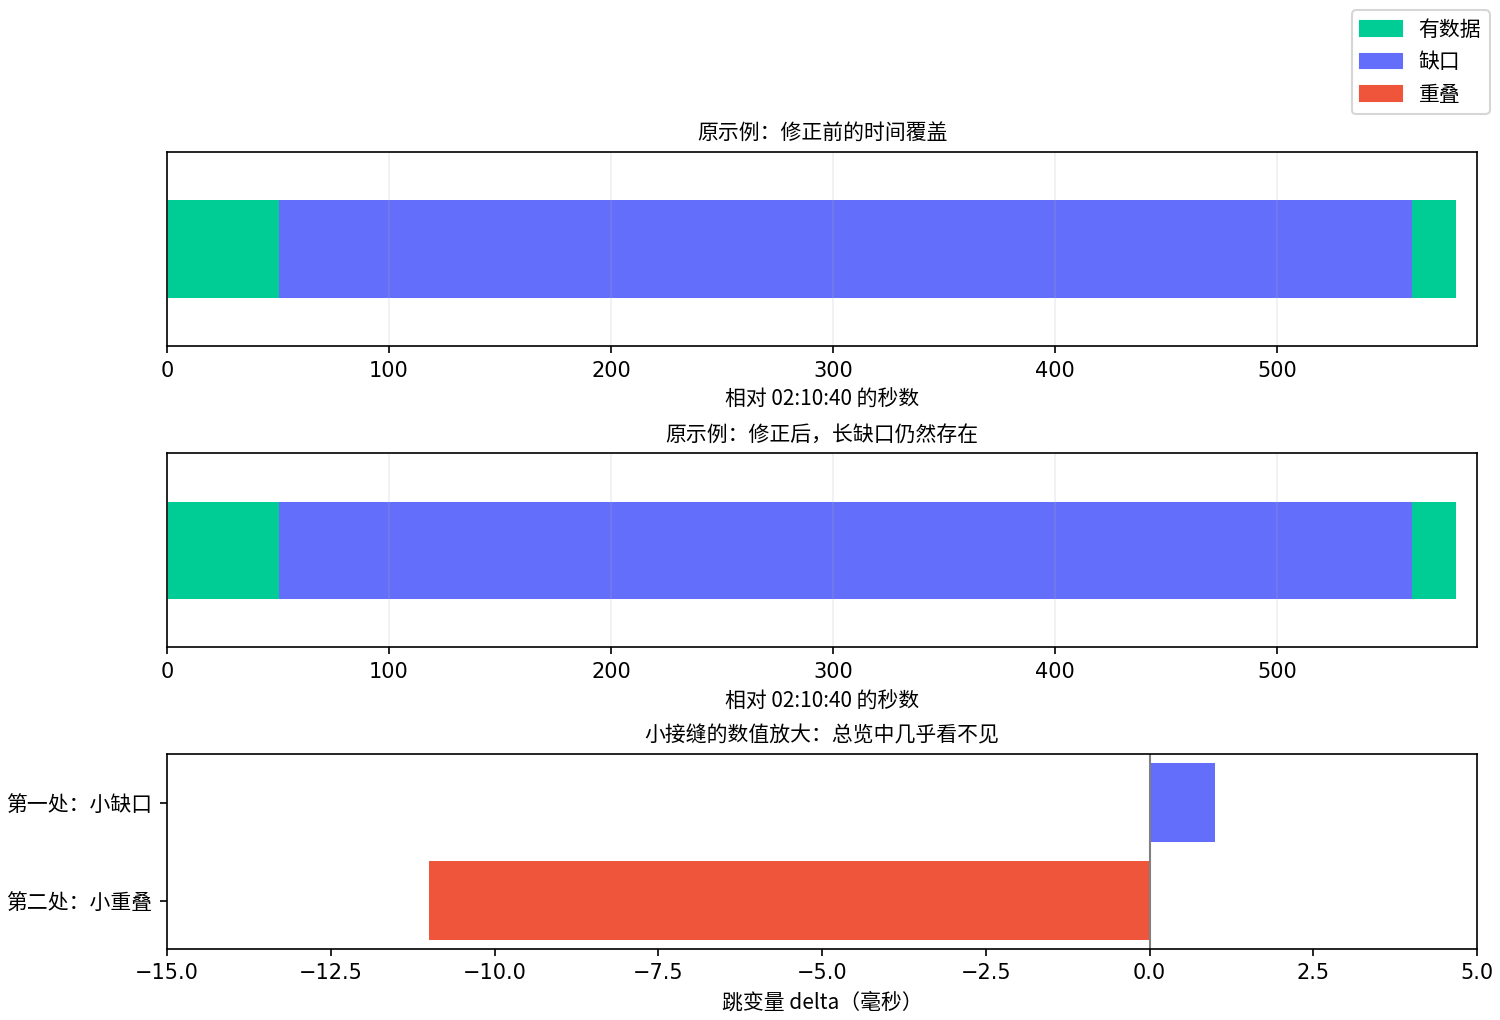

原代码生成的是 Plotly 交互图；若本地预览没有加载交互图，仍可看这张内嵌 PNG。需要查看你自己的结果时，使用上方重新生成的图和表格。

### **2.4 时间戳偏差与重复采样，要用不同处理**

实际使用时，可以直接将适当的 `tolerance` 传给 `xd.open`，在扫描、连接文件时处理小偏差。原教程拆成“打开 → 检查 → 修正”，是为了展示问题。`simplify` 还支持 `regularize=True`，在同一操作中尝试声明采样间隔；具体接口以项目版本为准。

| 情况 | 处理思路 | 原因 |
| --- | --- | --- |
| 样本有效，时间戳存在小偏差 | 在有依据的容差内调整坐标，如 `simplify` | 问题在时间标签 |
| 相同时间段的样本确实重复记录 | 使用 `xd.trim_overlaps(da)` 去除重叠样本 | 问题在重复记录，仅改标签不能解决 |
| 真实缺少一段记录 | 保留缺口，决定后续如何按连续段处理 | 改坐标无法恢复不存在的测量 |

`xd.trim_overlaps` 默认保留较后的副本；这是按重叠坐标裁剪的工具，不会自动证明两份数据数值完全相同。裁剪可在元数据层面完成，维持惰性读取；并非删除磁盘上的原始文件。

本节正文没有调用 `trim_overlaps`。表格用于解释不同问题的处理选择，不要求在当前 `ntp` 上追加执行。

## **3. 替换已有坐标：距离从米改为千米**

回到光纤数据 `da`。给已有坐标名称赋新值会替换它；新坐标长度必须与对应维度相符。

下一格构造两端的索引—坐标值控制点：索引从 `0` 到最后一个通道，距离从 `0.0` 到原末端距离除以 `1000`。这是把本示例从零开始、均匀采样的距离刻度改为千米表示，**不是对波形做重采样**。

为什么只用两个端点？本示例距离轴可用线性关系表示。若实际光纤起点不为零、坐标不规则或存在特殊分段，不能直接套用这两个端点，应正确转换所有必要控制点。

In [11]:
distance = {
    "tie_indices": [0, da.sizes["distance"] - 1],
    "tie_values": [0.0, da["distance"].values[-1] / 1000],  # 米转换为千米
}
da = da.assign_coords(distance=distance)
da

<xdas.DataArray (time: 37500, distance: 10000)>
VirtualSource: 715.3MB (int16)
Coordinates:
  * distance (distance): 0.000 to 153.180
  * time (time): 2023-11-03T12:20:01.000 to 2023-11-03T12:30:00.984
    latitude (distance): [nan ... nan]
    longitude (distance): [nan ... nan]

### **为什么波形没有改变？**

这一步改的是 `distance` 标签；样本数、数据类型和测量值保持不变。原末端约 153179.709 m，转换后约 153.180 km。后续如果误把 `slice(4.6, 102.0)` 当作米，就会选错位置。

重新赋值后的 `da` 带新坐标，之前的 `ntp` 仍独立存在。

新建的坐标字典只给出了控制点，没有明确声明采样间隔。下一格读取采样间隔时，原示例会出现 **`FutureWarning`**：当前版本从坐标推断间隔，但这种隐式推断将来可能不再支持。

这是作者刻意展示“坐标值看似等间隔”与“软件明确知道采样间隔”的区别。若你的版本已将此提示改成异常，读完示例后继续执行下一格 `to_regular()`，再读取间隔；不要以此认定数据损坏。

In [12]:
xd.get_sampling_interval(da, "distance")

/tmp/ipykernel_421013/2202782207.py:1: FutureWarning: coordinate 'distance' has no declared sampling interval; inferred 0.01531950286162022 (accepting jitter up to tolerance=1.1368683772161603e-13). This implicit inference is deprecated and will raise in a future release; make the coordinate regular with `da['distance'] = da['distance'].to_regular(tolerance=...)`, or open the files with a tolerance
  xd.get_sampling_interval(da, "distance")


np.float64(0.01531950286162022)

用 `to_regular()` 声明规则采样后，再读取间隔：

- `True` 表示坐标具备规则采样声明。
- 原示例约 `0.0153195 km`，即约 **15.32 m**。

单位由坐标值及使用约定决定：我们除以 1000 后使用千米，所以后续距离选择参数也必须用千米。**变量名仍是 `distance`，并不自动把数字解释成米。**

In [13]:
da["distance"] = da["distance"].to_regular()
print(da["distance"].isregular(), da["distance"].get_sampling_interval(), "km")

True 0.01531950286162022 km


## **4. 添加辅助坐标：经纬度与通道名称**

新名称对应的新坐标会被添加。给一维辅助坐标赋值时，通常用 `(依附的维度名, 坐标值数组)`，告诉软件它对应哪个轴。

`latitude`（纬度）和 `longitude`（经度）已经由教程一依据光纤路径信息加入，并随 `outputs/singlecable.nc` 保存到这里。下一格查看它们。它们依附于距离维度；现在还不是维度本身。

In [14]:
da["latitude"], da["longitude"]

([nan ... nan], [nan ... nan])

### **4.1 什么是盘纤？为什么这里要裁掉一部分区段？**

**盘纤，就是把一段光纤绕成圈，盘放在一个较小的空间里。**常见于岸站、机房或接头盒，用来安置预留的光纤长度。

理解盘纤时，要区分两种距离：**沿着光纤走过的长度**与**实际地理位置的变化**。例如，把 1 km 光纤绕成很多圈放在机房里，DAS 仍然可以沿这 1 km 光纤划分出很多测量通道，但这些通道可能都位于同一间机房。

| 比较项 | 盘在机房里的光纤 | 沿实际路径铺设的光纤 |
| --- | --- | --- |
| 沿纤距离 | 沿着光纤继续增加 | 沿着光纤继续增加 |
| 地理位置 | 集中在小范围内，经纬度可能相同或非常接近 | 随路径变化；纬度不一定始终递增 |
| DAS 通道 | 不同沿纤位置仍对应不同通道 | 不同沿纤位置对应不同通道 |

所以，**沿纤距离不同，不保证经纬度不同**。盘纤也可以测到附近的振动，不是没有信号，更不能仅凭“盘纤”认定数据无效。

#### **为什么本教程排除盘纤段？**

原教程说明：本示例 `SER/N` 光纤岸站前约 **4.6 km** 为盘纤，路径坐标中多个通道重复同一位置。后面要把纬度作为范围选择轴，重复的纬度不满足该示例所需的严格单调条件，因此先排除这一段。**这是为当前地理坐标操作选择区段，不是所有 DAS 分析都必须删除盘纤。**

另一个独立问题是：已测绘路径约止于 **102 km**，但采集范围达到约 **153 km**，末段没有可靠的经纬度，记为 `NaN`（缺失值）。这些通道可能仍有波形，只是没有对应的位置资料，不能凭空补造经纬度。

因此，下一格保留约 **4.6–102 km** 的已测绘、非盘纤区段，再检查纬度缺失值。

这些边界来自原教程对这根光纤的说明，不是通用裁剪范围。**没有纬度缺失值不等于已经证明严格单调**；即使排除了盘纤，弯折路径仍可能让纬度重复或改变增减方向，应检查实际坐标。


In [15]:
da = da.sel(distance=slice(4.6, 102.0))  # 单位为千米：避开盘纤，限制在已测绘区间
np.isnan(da["latitude"].values).any()

np.False_

输出 `False` 表示裁剪区间中没有纬度 `NaN`。若得到 `True`，应先检查实际几何数据和裁剪范围，不要直接进入纬度选择。

需要自行检查递增性时，可在这里用下面的可选代码；不必加入原正文运行序列：

```python
lat = da["latitude"].values
print("纬度全部有限：", np.isfinite(lat).all())
print("纬度严格递增：", np.all(np.diff(lat) > 0))
```

本例预期递增；其他光纤若递减或折返，应按实际路径处理，而不是为通过检查随意重排时间—通道对应关系。

### **4.2 给通道添加示例台站名称**

下一格创建 `station` 辅助坐标，附着到 `distance` 维度。`f"D{i:05d}"` 表示用 `D` 加五位补零编号，例如 `D00000`、`D00001`。

目的是让光纤通道也能以名称与地震台站等记录配合使用。**这是裁剪后重新编号的示例标签，不是原仪器通道号，也不是正式注册的台站代码。**如果研究需要追溯原始通道，应另行保留原编号或映射关系。

In [16]:
da = da.assign_coords(
    station=("distance", np.array([f"D{i:05d}" for i in range(da.sizes["distance"])]))
)
da

<xdas.DataArray (time: 37500, distance: 6358)>
VirtualSource: 454.8MB (int16)
Coordinates:
  * distance (distance): 4.611 to 101.997
  * time (time): 2023-11-03T12:20:01.000 to 2023-11-03T12:30:00.984
    latitude (distance): [-29.88896955 ... -29.23674116]
    longitude (distance): [-71.27435372 ... -71.72596951]
    station (distance): ['D00000' ... 'D06357']

### **4.3 空间降采样后，辅助坐标也要跟随**

下一格把空间采样率降低为原来的 `1/16`，结果放入新变量 **`decimated`**；原变量 `da` 不会因此被替换。

作者用它展示：降采样后，通道名称与纬度仍对应保留的空间位置。原输出前四个名称为 `D00000`、`D00016`、`D00032`、`D00048`，不是把旧标签留在原索引上。

**`xd.resample` 不只是数组每隔 16 点取一个值。**默认 FIR 方法包含低通抗混叠处理，沿距离轴作用，波形值可能变化；新空间间隔约为 `16 × 15.32 m ≈ 245 m`。这里的 16 用来演示坐标跟随，原教程未提供针对该波场的最优比例论证。降低空间采样率会损失细空间尺度信息。

辅助标签的正确跟随不等于新波形完全属于一个孤立通道；滤波会综合邻近空间样本。

In [17]:
decimated = xd.resample(da, down=16, dim="distance")
decimated["station"].values[:4], decimated["latitude"].values[:4]

(array(['D00000', 'D00016', 'D00032', 'D00048'], dtype='<U6'),
 array([-29.88896955, -29.88841105, -29.88785264, -29.88729412]))

## **5. 将辅助坐标提升为维度坐标**

`swap_dims` 让已附着在轴上的辅助坐标成为新的维度坐标。下一格用纬度替代距离：通道对应关系不变，维度名变为 `latitude`，原来的 `distance` 仍作为辅助坐标保留。

作者这样做是为了按地理位置选择光纤片段。应选择无缺失、适合范围选择的严格单调坐标；本例裁剪后的纬度随沿纤位置递增。

**这不是转置，不是地理投影，也不是把波形插值到等纬度网格。**不同光纤可能弯折，纬度可能重复或先增后减，不能直接照搬这一步。

In [18]:
da = da.swap_dims({"distance": "latitude"})
da

<xdas.DataArray (time: 37500, latitude: 6358)>
VirtualSource: 454.8MB (int16)
Coordinates:
    distance (latitude): 4.611 to 101.997
  * time (time): 2023-11-03T12:20:01.000 to 2023-11-03T12:30:00.984
  * latitude (latitude): [-29.88896955 ... -29.23674116]
    longitude (latitude): [-71.27435372 ... -71.72596951]
    station (latitude): ['D00000' ... 'D06357']

### **维度替换后发生了什么？**

原示例从 `(time: 37500, distance: 6358)` 变成 `(time: 37500, latitude: 6358)`，通道数量没变。`latitude` 获得 `*`，`distance`、`longitude`、`station` 改为依附于纬度维度的辅助坐标。

**没有调用 `transpose`，数据轴顺序仍是时间、空间；也没有调用 `resample`，各样本仍对应原来的通道。**后续 `sel(latitude=...)` 才按新标签选择数据。

### **5.1 现在用纬度范围选择数据**

下一格同时选择约 70 秒的时间窗口，以及 **−29.7° 到 −29.4°** 的纬度范围。这些是原教程选择的事件展示范围，不是算法自动确定的最佳窗口。

南纬用负数表示：−29.4° 比 −29.7° 更靠北。这里纬度递增，所以上下界按这个顺序写。对其他路径，应先确认单调方向及项目版本的选择规则。

注意变量来源：下一格操作的是 **`da`，不是刚才的 `decimated`**，因此最后图没有使用那次 16 倍空间降采样的结果。

In [19]:
da = da.sel(
    time=slice("2023-11-03T12:26:40", "2023-11-03T12:27:50"),
    latitude=slice(-29.7, -29.4),
)
da

<xdas.DataArray (time: 4375, latitude: 2496)>
VirtualSource: 20.8MB (int16)
Coordinates:
    distance (latitude): 45.162 to 83.384
  * time (time): 2023-11-03T12:26:40.008 to 2023-11-03T12:27:49.992
  * latitude (latitude): [-29.69999575 ... -29.40010654]
    longitude (latitude): [-71.62067085 ... -71.73727898]
    station (latitude): ['D02647' ... 'D05142']

### **最后一次选择的结果**

原示例保留 `4375` 个时间样本和 `2496` 个空间样本，实际首尾时间落在采样格点上，所以不必与请求的时间边界字面完全相同。沿纤距离约为 45.16–83.38 km，仍可通过辅助坐标查看。

下一格仅绘图：`x="time"` 将时间放到横轴，空间轴使用当前的纬度，`yincrease=True` 让纬度值向上增大。

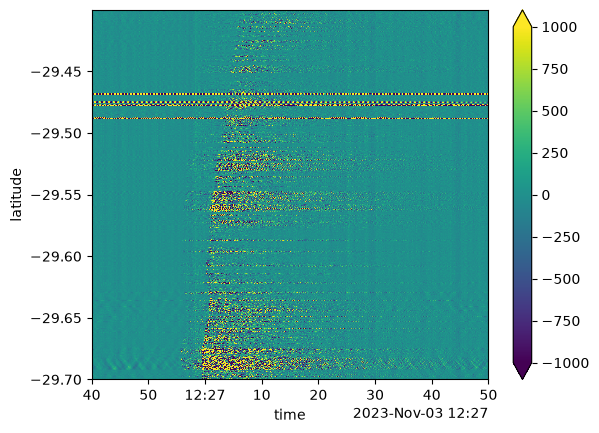

In [20]:
da.plot(x="time", yincrease=True, vmin=-1000, vmax=1000)

## **6. 最后的纬度—时间图怎样读？**

### **坐标与颜色**

- 横轴为时间，约 2023-11-03 12:26:40–12:27:50；纵轴为南纬约 −29.7° 到 −29.4°，向上更靠北。
- 颜色是选中波形的**带正负号的原测量值**，显示范围 −1000 到 +1000；色标外的值饱和到端部颜色。
- 本教程没有对这张图追加高通、取绝对值或震相预测。它来自 `singlecable.nc` 的选中窗口，物理单位应按原数据标定确认，不能直接标成速度或位移。

### **示例中能观察到什么？**

原输出在约 12:27:00 前后出现更明显的波动，并在后续数十秒逐渐减弱；不同纬度位置出现时间和纹理不同。约 −29.48° 附近存在持续的水平强条纹，表示固定地理位置附近在较长时间内具有较大的测量幅度，不等于已经查明它是坏通道或某个特定振动源。

条纹与之前以距离作横轴、时间作纵轴的图方向不同，是因为这张图把时间放在横轴、空间放在纵轴。**方向改变不代表传播方向改变。**

### **能否据此判断传播速度或 P、S？**

不能直接用“纬度差 ÷ 时间差”当作沿纤传播速度。纬度是角度，不是沿纤长度；弯曲路线会改变纬度与距离之间的关系。若需要沿纤视速度，应回到距离坐标，结合到时与几何分析。本图没有 P、S 标记，不能仅凭颜色确认震相。

纬度样本也未必等间隔。用于定量解释时，要确认绘图方法是否准确表达非均匀坐标位置，不能只用屏幕上的等宽像素测量距离。

## **本教程完成后应掌握什么？**

能够区分时间戳偏差、重复记录和真实缺口；理解距离单位变换只改坐标、空间重采样会改变波形；知道辅助坐标随样本保留，并在条件满足时成为选择轴。

本例结果留在内存，没有新增保存步骤。若重启内核，需按顺序重新运行；如果重复执行“米转千米”那一格，会再次除以 1000，因此应从打开 `da` 的单元格重新开始该部分。

## **术语与依据**

| 英文 | 本教程采用的中文 |
| --- | --- |
| coordinate / axis coordinate | 坐标／轴坐标 |
| tie point | 索引—坐标值控制点，不译为“连接点” |
| jitter / tolerance | 抖动／容差 |
| gap / overlap / seam | 缺口／重叠／文件接缝 |
| regular / strictly monotonic | 规则采样／严格单调，两者不同 |
| nominal sampling interval | 标称采样间隔 |
| coiled fiber / surveyed route | 盘纤／已测绘路径 |
| decimation / auxiliary coordinate | 降采样／辅助坐标 |

NTP 采集背景、盘纤与路径范围来自原教程说明；参数 30 ms、16 倍降采样、展示窗口不是普适最优值。目的和原理解释属于中文版补充，其中没有把未说明的参数动机写成作者结论。

可核对的原始来源：

1. [教程四原文](https://github.com/xdas-dev/tutorials/blob/main/04_playing_with_coordinates.ipynb)：代码、数据背景与原示例输出。
2. [XDAS 坐标简化](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.coordinates.InterpCoordinate.simplify.html)：简化与容差。
3. [XDAS 坐标实现](https://xdas.readthedocs.io/en/latest/_modules/xdas/coordinates/core.html)：规则采样与转换接口。
4. [XDAS 重采样](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.resample.html)：默认 FIR 抗混叠及采样比例。
5. [XDAS 重叠裁剪](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.trim_overlaps.html)：重叠记录处理。

文档可能随版本更新；如果网页打不开，本 Notebook 已保留必要说明，但 API 使用仍应与项目环境匹配。